## The Roads Table
This is the table of the cities we chose and the distances between them from getting from Nairobi to Kisumu and the respective cities in between

| From     | To       | Main road | Distance (km) |
|----------|----------|-----------|---------------|
| Nairobi  | Thika    | A2        | 45            |
| Nairobi  | Naivasha | A8        | 91            |
| Nairobi  | Narok    | B3        | 143           |
| Thika    | Nyeri    | A2        | 113           |
| Nyeri    | Nakuru   | B5        | 167           |
| Naivasha | Nakuru   | A8        | 70            |
| Narok    | Kericho  | B3 / C23  | 157           |
| Nakuru   | Kericho  | B1        | 107           |
| Nakuru   | Eldoret  | A8        | 156           |
| Kericho  | Kisumu   | B1        | 84            |
| Eldoret  | Kakamega | A1        | 80            |
| Kakamega | Kisumu   | A1 / A8   | 107           |

### The directed graph from the above table

In [2]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# Directed graph from Part 1: town -> {neighbouring town: distance in km}
highway = {
    "Nairobi":  {"Thika": 45, "Naivasha": 91, "Narok": 143},
    "Thika":    {"Nyeri": 113},
    "Nyeri":    {"Nakuru": 167},
    "Naivasha": {"Nakuru": 70},
    "Narok":    {"Kericho": 157},
    "Nakuru":   {"Kericho": 107, "Eldoret": 156},
    "Kericho":  {"Kisumu": 84},
    "Eldoret":  {"Kakamega": 80},
    "Kakamega": {"Kisumu": 107},
    "Kisumu":   {},
}

# Road names, kept for the final report
road_names = {
    ("Nairobi", "Thika"): "A2",    ("Nairobi", "Naivasha"): "A8",
    ("Nairobi", "Narok"): "B3",    ("Thika", "Nyeri"): "A2",
    ("Nyeri", "Nakuru"): "B5",     ("Naivasha", "Nakuru"): "A8",
    ("Narok", "Kericho"): "B3/C23",("Nakuru", "Kericho"): "B1",
    ("Nakuru", "Eldoret"): "A8",   ("Kericho", "Kisumu"): "B1",
    ("Eldoret", "Kakamega"): "A1", ("Kakamega", "Kisumu"): "A1/A8",
}

START, GOAL = "Nairobi", "Kisumu"


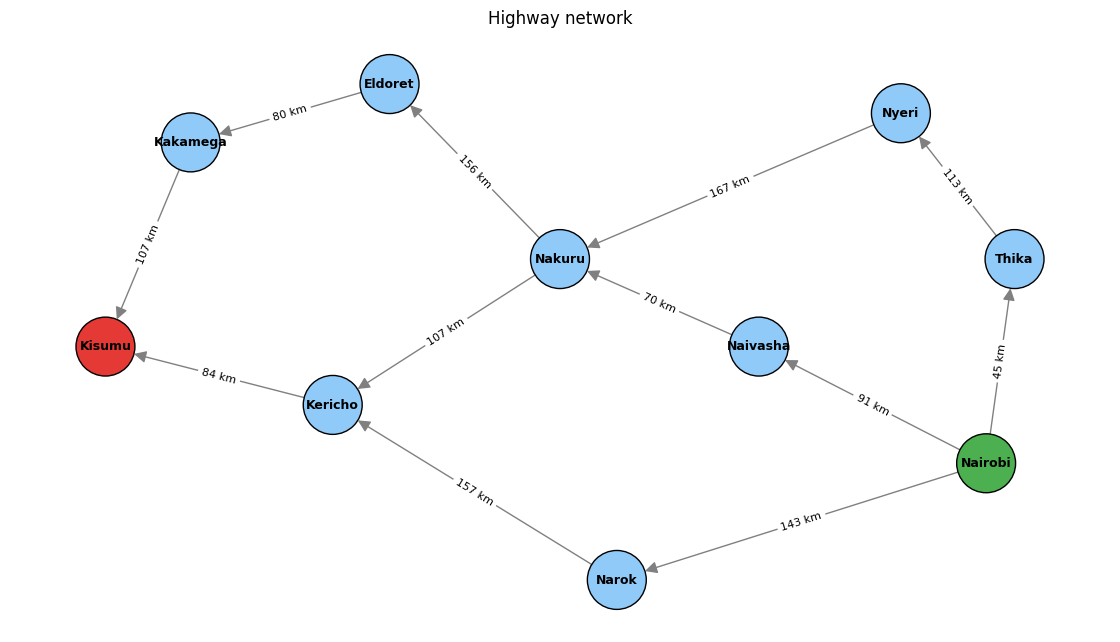

In [4]:

positions = {
    "Kisumu":(0,0), "Kakamega":(0.6,1.4), "Eldoret":(2,1.8),
    "Kericho":(1.6,-0.4), "Nakuru":(3.2,0.6), "Narok":(3.6,-1.6),
    "Naivasha":(4.6,0), "Nyeri":(5.6,1.6), "Thika":(6.4,0.6),
    "Nairobi":(6.2,-0.8)
}

def build_nx_graph():
    G = nx.DiGraph()
    for town, roads in highway.items():
        for next_town, km in roads.items():
            G.add_edge(town, next_town, weight=km)
    return G

def draw_graph(G, highlight_path=None, title="Highway network"):
    plt.figure(figsize=(11,6))

    path_edges = list(zip(highlight_path, highlight_path[1::])) if highlight_path else []

    colors = [
        "#4caf50" if n == START else
        "#e53935" if n == GOAL else
        "#ffb300" if highlight_path and n in highlight_path else
        "#90caf9"
        for n in G.nodes
    ]

    nx.draw(G, positions, with_labels=True, node_color=colors,
            node_size=1800, edgecolors="black", arrowsize=18,
            font_size=9, font_weight="bold", edge_color="grey")

    if path_edges:
        nx.draw_networkx_edges(G, positions, edgelist=path_edges,
                               edge_color="#e65100", width=3.5,
                               arrowsize=22, node_size=1800)

    labels = {(u,v): f"{d['weight']} km" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, positions, edge_labels=labels, font_size=8)

    plt.title(title)
    plt.axis("off")
    plt.show()

G = build_nx_graph()
draw_graph(G)


        




### Uniform Cost Search Implementation
- It will work by us putting the start node in the frontier which is a priority queue ordered by a path of cost g
- We then pop the node with the lowest g from the frontier and perform a goal test
- Adding the town to the explored set
- From each neighbouring town if it is neither explored nor in the frontier we add it, if it is already there with a higher cost we replace it with the cheaper path

In [5]:
def uniform_cost_search(graph, start, goal, show_steps=True):
    # Each frontier entry is (path cost g, town, path taken to reach it)
    frontier = [(0, start, [start])]
    best_g_in_frontier = {start: 0}   # cheapest known cost for each town still in the frontier
    explored = set()
    step = 0

    while frontier:
        g, town, path = heapq.heappop(frontier)

        # Skip stale entries (a cheaper path to this town was found after this one was pushed)
        if town in explored or best_g_in_frontier.get(town) != g:
            continue
        del best_g_in_frontier[town]
        step += 1

        if show_steps:
            print(f"\nSTEP {step}")
            print(f"  Expand : {town:<9} g = {g:>3}   path = {' -> '.join(path)}")

        # Goal test when the node is removed from the frontier
        if town == goal:
            if show_steps:
                print(f"  GOAL TEST: {town} is the goal -> stop searching")
            return path, g, step

        explored.add(town)

        for neighbour, distance in graph[town].items():
            new_g = g + distance
            if neighbour in explored:
                note = "already explored -> ignored"
            elif neighbour not in best_g_in_frontier:
                heapq.heappush(frontier, (new_g, neighbour, path + [neighbour]))
                best_g_in_frontier[neighbour] = new_g
                note = "added to frontier"
            elif new_g < best_g_in_frontier[neighbour]:
                old = best_g_in_frontier[neighbour]
                heapq.heappush(frontier, (new_g, neighbour, path + [neighbour]))
                best_g_in_frontier[neighbour] = new_g
                note = f"cheaper than {old} -> replaced in frontier"
            else:
                note = f"in frontier with g = {best_g_in_frontier[neighbour]} (cheaper) -> not added"
            if show_steps:
                print(f"    {town} -> {neighbour:<9} g = {g} + {distance} = {new_g:<4} {note}")

        if show_steps:
            current = sorted(best_g_in_frontier.items(), key=lambda x: x[1])
            print("  Frontier :", ", ".join(f"{t}({c})" for t, c in current) or "empty")
            print("  Explored :", ", ".join(sorted(explored)))

    return None, float("inf"), step   # failure: goal not reachable


print(f"Uniform Cost Search from {START} to {GOAL}")
print("=" * 60)
optimal_path, optimal_cost, steps = uniform_cost_search(highway, START, GOAL)

Uniform Cost Search from Nairobi to Kisumu

STEP 1
  Expand : Nairobi   g =   0   path = Nairobi
    Nairobi -> Thika     g = 0 + 45 = 45   added to frontier
    Nairobi -> Naivasha  g = 0 + 91 = 91   added to frontier
    Nairobi -> Narok     g = 0 + 143 = 143  added to frontier
  Frontier : Thika(45), Naivasha(91), Narok(143)
  Explored : Nairobi

STEP 2
  Expand : Thika     g =  45   path = Nairobi -> Thika
    Thika -> Nyeri     g = 45 + 113 = 158  added to frontier
  Frontier : Naivasha(91), Narok(143), Nyeri(158)
  Explored : Nairobi, Thika

STEP 3
  Expand : Naivasha  g =  91   path = Nairobi -> Naivasha
    Naivasha -> Nakuru    g = 91 + 70 = 161  added to frontier
  Frontier : Narok(143), Nyeri(158), Nakuru(161)
  Explored : Nairobi, Naivasha, Thika

STEP 4
  Expand : Narok     g = 143   path = Nairobi -> Narok
    Narok -> Kericho   g = 143 + 157 = 300  added to frontier
  Frontier : Nyeri(158), Nakuru(161), Kericho(300)
  Explored : Nairobi, Naivasha, Narok, Thika

STEP 5
  

### Drawing the graph of the most optimal path

OPTIMAL ROUTE FOUND BY UCS
Leg  From      To        Road       km      g
---------------------------------------------
1    Nairobi   Naivasha  A8         91     91
2    Naivasha  Nakuru    A8         70    161
3    Nakuru    Kericho   B1        107    268
4    Kericho   Kisumu    B1         84    352
---------------------------------------------
Path       : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost : 352 km
Nodes expanded: 9


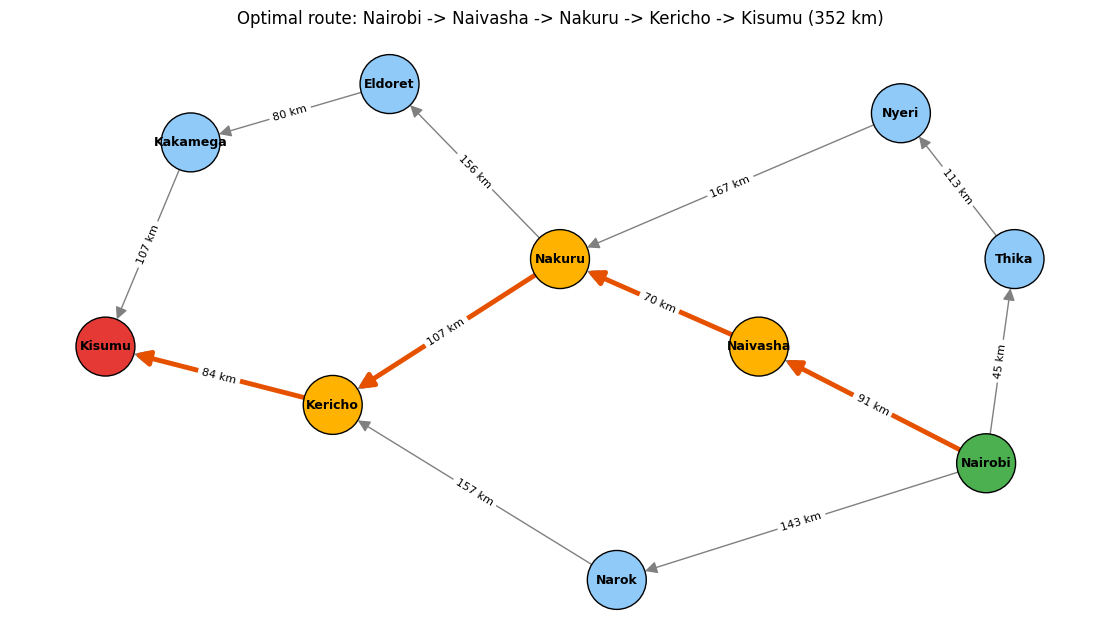

In [7]:
if optimal_path is None:
    print("No route found.")
else:
    print("OPTIMAL ROUTE FOUND BY UCS")
    print("=" * 50)
    print(f"{'Leg':<5}{'From':<10}{'To':<10}{'Road':<8}{'km':>5}{'g':>7}")
    print("-" * 45)
    running = 0
    for i, (a, b) in enumerate(zip(optimal_path, optimal_path[1:]), start=1):
        running += highway[a][b]
        print(f"{i:<5}{a:<10}{b:<10}{road_names[(a, b)]:<8}{highway[a][b]:>5}{running:>7}")
    print("-" * 45)
    print(f"Path       : {' -> '.join(optimal_path)}")
    print(f"Total cost : {optimal_cost} km")
    print(f"Nodes expanded: {steps}")

draw_graph(G, highlight_path=optimal_path,
           title=f"Optimal route: {' -> '.join(optimal_path)} ({optimal_cost} km)")

### Listing every route 
To confirm that UCS returned the optimal path we listed evey route with their costs

In [12]:
def all_routes(graph, town, goal, path=None, cost=0):
    path = (path or []) + [town]
    if town == goal:
        return [(cost, path)]
    routes = []
    for nxt, km in graph[town].items():
        if nxt not in path:
            routes += all_routes(graph, nxt, goal, path, cost + km)
    return routes

routes = sorted(all_routes(highway, START, GOAL))
print(f"{'Rank':<6}{'Cost (km)':<11}Route")
print("-" * 70)
for rank, (cost, path) in enumerate(routes, start=1):
    mark = "  <-- UCS answer" if path == optimal_path else ""
    print(f"{rank:<6}{cost:<11}{' -> '.join(path)}{mark}")

assert routes[0][1] == optimal_path, "UCS did not return the cheapest route"
print("\nCheck passed: the UCS route is the cheapest of all", len(routes), "routes.")

Rank  Cost (km)  Route
----------------------------------------------------------------------
1     352        Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu  <-- UCS answer
2     384        Nairobi -> Narok -> Kericho -> Kisumu
3     504        Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu
4     516        Nairobi -> Thika -> Nyeri -> Nakuru -> Kericho -> Kisumu
5     668        Nairobi -> Thika -> Nyeri -> Nakuru -> Eldoret -> Kakamega -> Kisumu

Check passed: the UCS route is the cheapest of all 5 routes.


To conlcide, UCS found the optimal route, Nairobi, Naivasha, Nakuru, Kericho, Kisumu with the total cost of 352 km which matches the cheapest leaf of 352 in the search tree which was drawn.

![PS-Agents group meeting](<Screenshot 2026-10-14 213950.png>)